# Compare track length between NEW (10.1 bar) and NEXT-100 (4 bar)

In [1]:
import os, sys
sys.path.append('../')

import pandas as pd
import numpy as np

from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

from pathlib import Path
import importlib

In [2]:

plt.rcParams.update({
    # Use LaTeX for text rendering
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],

    # Font sizes (match your LaTeX doc's font size)
    "font.size": 12*2,
    "axes.titlesize": 28.9,
    "axes.labelsize": 28.9,
    "xtick.labelsize": 27.6,
    "ytick.labelsize": 27.6,
    "legend.fontsize": 26,

    # Figure size — match LaTeX text width
    # For A4 with default margins: ~6.3in wide
    "figure.figsize": (5.9, 5.9),  # golden ratio height

    # Line/marker quality
    "lines.linewidth": 1.5,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,

    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
})



In [3]:
# load in data
timestamp = '456015'
data = pd.read_hdf(f'/home/e78368jw/Documents/topology_data/p_scan_140526/{timestamp}/full_dataset_15589_15590_15591_15593_15594_{timestamp}.h5', 'Tracking/Tracks') 
display(data)


,event,trackID,energy,length,numb_of_voxels,numb_of_hits,numb_of_tracks,x_min,y_min,z_min,...,blob1_z,blob2_x,blob2_y,blob2_z,eblob1,eblob2,ovlp_blob_energy,vox_size_x,vox_size_y,vox_size_z
0,3801498,0,1.466295,249.314697,412,970,1,-65.775,-0.875,749.814750,...,768.982559,-3.575,44.775,813.748853,0.435425,0.263727,0.0,14.380000,14.517647,13.617089
11,1556423,0,1.593040,219.540974,278,710,1,-204.725,-186.475,403.483375,...,421.119094,-50.225,-109.725,455.562835,0.555350,0.501672,0.0,14.575000,14.170833,13.848063
22,2335194,0,1.589335,179.527229,249,673,1,-126.975,75.875,197.231000,...,220.931227,-50.225,122.525,279.887646,0.691032,0.640770,0.0,13.954545,14.276923,14.346328
13,2130640,0,1.412268,256.847131,347,894,1,26.525,44.775,841.667750,...,994.685363,149.925,75.875,890.566908,0.531808,0.300295,0.0,14.170833,14.367857,14.426269
27,2798454,0,1.673739,281.979679,358,875,1,-34.675,-202.025,157.091000,...,231.221065,104.275,-155.375,308.940500,0.655274,0.168139,0.0,14.296429,14.453125,13.923063
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2,3187569,0,1.632569,190.033299,359,969,1,88.725,-47.525,746.388125,...,866.252937,165.475,29.225,782.471962,0.653753,0.422715,0.0,14.045455,14.045455,14.131864
1,3361232,0,1.690998,183.124444,353,964,1,-112.425,-217.575,977.920750,...,1011.839058,-19.125,-170.925,1012.342778,0.533263,0.530237,0.0,14.296429,14.517647,13.478700
0,1457260,0,1.587386,206.987196,385,988,1,-235.825,-202.025,345.336375,...,381.435531,-142.525,-47.525,390.486622,0.584859,0.269674,0.0,14.170833,14.453125,14.416906
7,2803094,0,1.498167,371.615340,281,640,1,26.525,-31.975,139.886500,...,174.713310,104.275,13.675,412.405074,0.716998,0.168322,0.0,13.895000,14.200000,14.797643


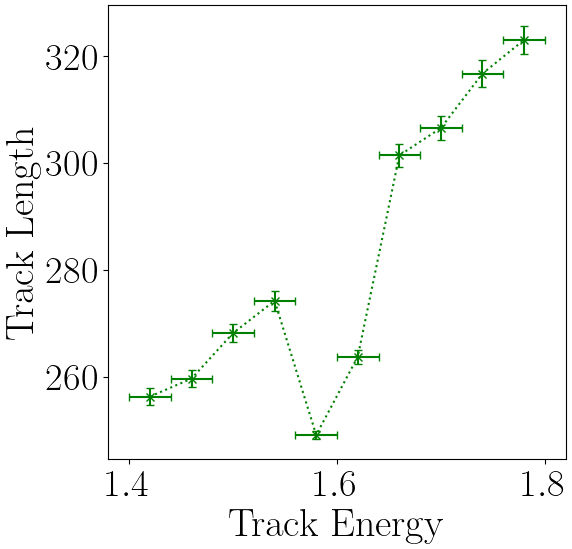

In [4]:
from scipy.stats import binned_statistic

df = data

binning = 10

means,  bin_edges, _ = binned_statistic(df['energy'], df['length'], statistic='mean',  bins=binning)
stds,   _,         _ = binned_statistic(df['energy'], df['length'], statistic='std',   bins=binning)
counts, _,         _ = binned_statistic(df['energy'], df['length'], statistic='count', bins=binning)

bin_centres = (bin_edges[:-1] + bin_edges[1:]) / 2
bin_widths = (bin_edges[1:] - bin_edges[:-1]) / 2
errors = stds / np.sqrt(counts)

plt.errorbar(bin_centres, means, xerr=bin_widths, yerr=errors, fmt='x:g', capsize=3)
plt.xlabel('Track Energy')
plt.ylabel('Track Length')
plt.show()

In [5]:
print(list((bc, m) for bc, m in zip(bin_centres, means)))

[(np.float64(1.4200172090078231), np.float64(256.296633047351)), (np.float64(1.4600133561231967), np.float64(259.65010795784633)), (np.float64(1.5000095032385699), np.float64(268.1795558124877)), (np.float64(1.540005650353943), np.float64(274.2261274604709)), (np.float64(1.5800017974693166), np.float64(249.09464165412047)), (np.float64(1.6199979445846897), np.float64(263.7531317988018)), (np.float64(1.6599940917000633), np.float64(301.44151123375093)), (np.float64(1.6999902388154364), np.float64(306.5569676834243)), (np.float64(1.7399863859308098), np.float64(316.7542659285251)), (np.float64(1.7799825330461831), np.float64(323.04575607763815))]


In [6]:
NEW_dataset = [(1334.6774193548385, 84.61538461538461),
(1379.6082949308757, 88.19320214669051),
(1424.5391705069123, 91.54740608228983),
(1471.1981566820277, 94.23076923076923),
(1517.8571428571427, 97.13774597495527),
(1562.7880184331798, 97.36135957066188),
(1607.7188940092165, 93.55992844364937),
(1654.3778801843318, 107.64758497316637),
(1701.0368663594468, 112.79069767441861),
(1745.967741935484, 117.48658318425761),
(1792.6267281105988, 121.28801431127012),
(1837.557603686636, 126.43112701252237),
(1882.4884792626726, 129.11449016100178)]

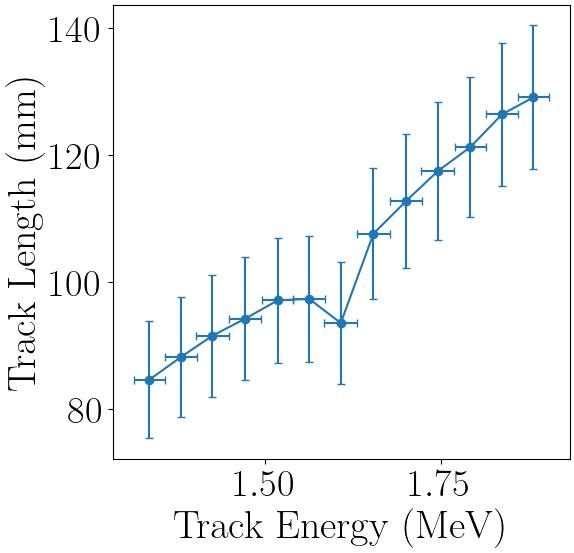

In [7]:
x = np.array([d[0] for d in NEW_dataset]) / 1000  # keV -> MeV
y = np.array([d[1] for d in NEW_dataset])

x_err = np.diff(x, append=x[-1] + (x[-1] - x[-2])) / 2
y_err = np.sqrt(y)

plt.errorbar(x, y, xerr=x_err, yerr=y_err, fmt='o-', capsize=3)
plt.xlabel('Track Energy (MeV)')
plt.ylabel('Track Length (mm)')
plt.show()

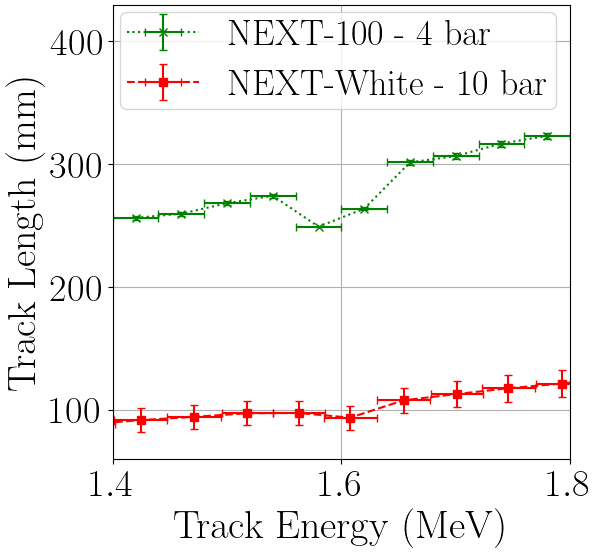

In [8]:
#mask = (bin_centres < 1.6) | (bin_centres > 1.625)

plt.errorbar(bin_centres, means, xerr=bin_widths, yerr=errors, fmt='x:g', capsize=3, label = 'NEXT-100 - 4 bar')
#plt.errorbar(bin_centres[mask], means[mask], xerr=bin_widths[mask], yerr=errors[mask], fmt='x:g', capsize=3)
plt.errorbar(x, y, xerr=x_err, yerr=y_err, fmt='s--r', capsize=3, label = 'NEXT-White - 10 bar')
plt.xlim([1.4, 1.8])
plt.ylim([60, 430])
plt.xlabel('Track Energy (MeV)')
plt.ylabel('Track Length (mm)')
plt.grid()
plt.legend(borderaxespad=0.2, loc = 'upper left', borderpad = 0.2)
plt.savefig('length_track_not_overlaid.pdf')
plt.savefig('length_track_not_overlaid.png')
plt.show()

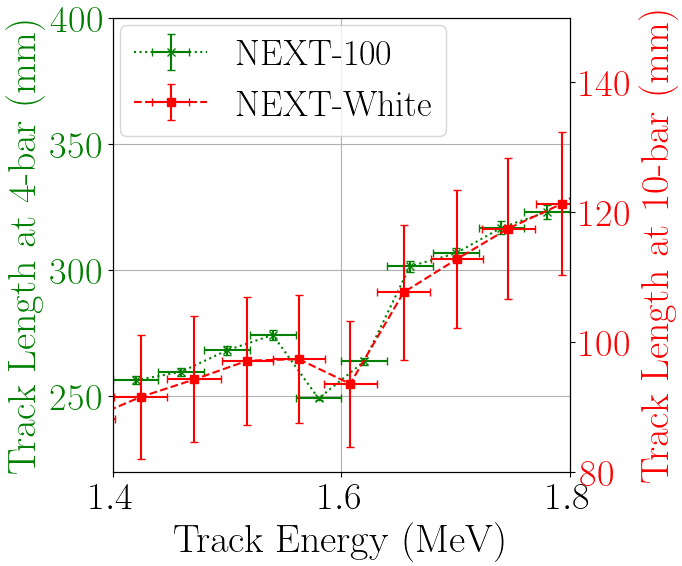

In [9]:
fig, ax1 = plt.subplots()

ax2 = ax1.twinx()

ax1.errorbar(bin_centres, means, xerr=bin_widths, yerr=errors, fmt='x:g', capsize=3, label='NEXT-100')
ax2.errorbar(x, y, xerr=x_err, yerr=y_err, fmt='s--r', capsize=3, label='NEXT-White')

ax1.set_xlabel('Track Energy (MeV)')
ax1.set_ylabel('Track Length at 4-bar (mm)', color='g')
ax2.set_ylabel('Track Length at 10-bar (mm)', color='r')
ax1.tick_params(axis='y', labelcolor='g')
ax2.tick_params(axis='y', labelcolor='r')

ax1.set_xlim([1.4, 1.8])
ax1.set_ylim([220, 400])
ax2.set_ylim([80, 150])

ax1.grid()

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, borderaxespad=0.2, loc = 'upper left')
plt.savefig('length_track_overlaid.pdf')
plt.savefig('length_track_overlaid.png')
plt.show()

In [17]:
# ratio between the two

# generate mask across shared track energies
m = (x >= bin_centres.min()) & (x <= bin_centres.max())

# interpolate N100 onto NEW data
N100_interp = np.interp(x[m], bin_centres, means)

ratio = N100_interp / y[m]
print(ratio)
print(ratio.mean())
print(ratio.std())

[2.80374713 2.78078322 2.78859406 2.66954858 2.77098213 2.75110077
 2.7202936  2.70409726]
2.7486433433759645
0.043609863256942674


In [12]:
# locate the bracketing N100 bins for each NEW energy
xm = x[m]
idx = np.searchsorted(bin_centres, xm, side="right") - 1
idx = np.clip(idx, 0, len(bin_centres) - 2)
t = (xm - bin_centres[idx]) / (bin_centres[idx + 1] - bin_centres[idx])

# interpolated N100 value and its error
A = (1 - t) * means[idx] + t * means[idx + 1]            # identical to np.interp
A_err = np.sqrt(((1 - t) * stds[idx])**2 + (t * stds[idx + 1])**2)

B, B_err = y[m], y_err[m]

# ratio and its error
R = A / B
R_err = R * np.hypot(A_err / A, B_err / B)

# combine into a single number (inverse-variance weighted mean)
w = 1 / R_err**2
R_mean = np.sum(w * R) / np.sum(w)
R_mean_err = 1 / np.sqrt(np.sum(w))

chi2 = np.sum(((R - R_mean) / R_err)**2)
ndf = len(R) - 1
print(f"R = {R_mean:.3f} ± {R_mean_err:.3f}, chi2/ndf = {chi2:.1f}/{ndf}")

R = 2.748 ± 0.223, chi2/ndf = 0.0/7


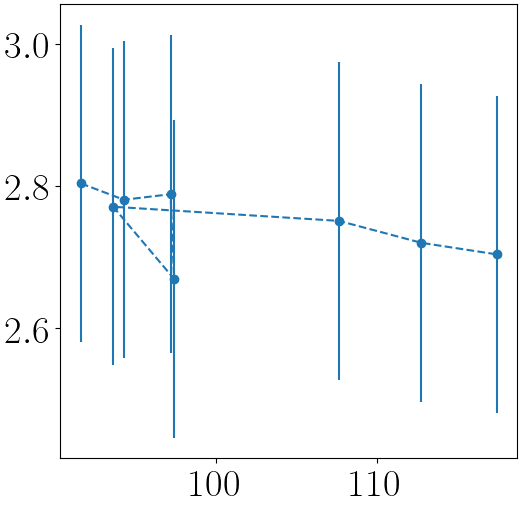

In [16]:
plt.errorbar(y[m], ratio, yerr = 0.223, linestyle = 'dashed', marker = 'o')
plt.show()